# Chapitre 16 - Exercices 16.1 à 16.4

- **16.1** : générer exactement les données corrélées par blocs de la section 16.2.3 ;
- **16.2** : longueur d'arc $L_1$ d'un chemin de coefficients et monotonie ;
- **16.3** : les règles-feuilles d'un arbre reproduisent l'arbre (régression et
  régression logistique) ;
- **16.4** : programmer la simulation « lasso contre ridge » de la figure 16.2.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from esl.plotting import set_style, COLORS, BLUE, ORANGE, GRAY, SEQ, DIV, TWO_CLASS
set_style()

from esl.ch16_ensembles import (block_correlated_data, standardize, forward_stagewise,
                                l1_arc_length, logistic_irls, ridge_path_df)

## Exercice 16.1 : Données gaussiennes corrélées par blocs

**Énoncé (reformulé).** Décrire précisément comment engendrer les données corrélées
par blocs utilisées dans la simulation de la section 16.2.3 (figures 16.3 et 16.4).

Rappel du cahier des charges donné par le livre : un dictionnaire de $p=1000$
variables gaussiennes, fortement corrélées ($\rho=0{,}95$) à l'intérieur de blocs de
20 variables et non corrélées entre blocs ; un modèle vrai avec 50 coefficients non
nuls, **un par bloc**, tirés selon une loi normale centrée réduite ; un bruit gaussien
avec un rapport bruit/signal de $0{,}72$ ; $N=60$ observations.

### Rappels

- Un vecteur gaussien $X\in\mathbb R^p$ est entièrement déterminé par sa moyenne et sa
  matrice de covariance $\Sigma$. Si $Z\sim\mathcal N(0,I_q)$ et $A$ est une matrice
  $p\times q$, alors $AZ\sim\mathcal N(0,AA^T)$.
- Le **rapport bruit/signal** est $\mathrm{NSR}=\operatorname{Var}(\varepsilon)/\operatorname{Var}(f(X))$
  où $Y=f(X)+\varepsilon$.

### Solution

**1. La matrice de covariance visée.** Numérotons les blocs $b=1,\dots,50$ ; le bloc
$b$ contient les variables $j\in B_b=\{20(b-1)+1,\dots,20b\}$. On veut
$\operatorname{Var}X_j=1$ et
$$
\operatorname{Cov}(X_j,X_k)=\begin{cases}\rho&\text{si }j\neq k\text{ sont dans le même bloc},\\0&\text{sinon.}\end{cases}
$$
Ainsi $\Sigma$ est diagonale par blocs, chaque bloc valant
$\Sigma_0=(1-\rho)I_{20}+\rho\,\mathbf 1\mathbf 1^T$ (matrice à 1 sur la diagonale et
$\rho$ ailleurs).

**2. Une construction simple par facteur commun.** Tirons indépendamment
$Z_1,\dots,Z_{50}\sim\mathcal N(0,1)$ (un facteur par bloc) et
$E_1,\dots,E_{1000}\sim\mathcal N(0,1)$, puis posons, pour $j\in B_b$,
$$
X_j=\sqrt\rho\,Z_b+\sqrt{1-\rho}\,E_j .
$$
- $X_j$ est gaussienne comme combinaison linéaire de gaussiennes indépendantes ;
- $\operatorname{Var}X_j=\rho\operatorname{Var}Z_b+(1-\rho)\operatorname{Var}E_j=\rho+(1-\rho)=1$ (indépendance) ;
- pour $j\ne k$ dans le même bloc, par bilinéarité de la covariance et indépendance,
  $\operatorname{Cov}(X_j,X_k)=\rho\operatorname{Var}Z_b=\rho$ ;
- pour $j,k$ dans deux blocs différents, $X_j$ et $X_k$ ne font intervenir que des
  variables indépendantes : $\operatorname{Cov}(X_j,X_k)=0$.

On obtient donc exactement $X\sim\mathcal N(0,\Sigma)$. (On pourrait aussi utiliser la
factorisation de Cholesky $\Sigma_0=LL^T$ et poser $X_{B_b}=LZ^{(b)}$ ; la construction
par facteur commun est plus économique et plus parlante.)

**3. Les coefficients.** Pour chaque bloc $b$, on choisit **une** variable $j_b\in B_b$
(au hasard, uniformément) et l'on tire $\beta_{j_b}\sim\mathcal N(0,1)$ ; tous les
autres $\beta_j$ sont nuls. Le signal est $f(X)=\sum_b\beta_{j_b}X_{j_b}$.

**4. Le niveau de bruit.** Les $X_{j_b}$ appartiennent à des blocs différents : ils
sont indépendants et de variance 1, donc
$$
\operatorname{Var}f(X)=\sum_b\beta_{j_b}^2=\|\beta\|^2 .
$$
Pour obtenir $\mathrm{NSR}=0{,}72$, on prend $\varepsilon\sim\mathcal N(0,\sigma^2)$ avec
$\sigma^2=0{,}72\,\|\beta\|^2$, et $Y=f(X)+\varepsilon$.

**5. Échantillons.** On tire $N=60$ vecteurs $X$ i.i.d. pour l'apprentissage ; pour
l'échantillon test, on **garde le même $\beta$** (et le même $\sigma$) et on tire de
nouveaux $X$ et $\varepsilon$. Enfin, comme dans la figure 16.3, les variables sont
standardisées avant d'ajuster lasso et forward stagewise. Cette procédure est codée
dans `block_correlated_data` du module `esl/ch16_ensembles.py`.

### Vérification numérique

Avec un grand échantillon, la matrice de corrélation empirique doit être proche de
$\Sigma$. Regardons les 60 premières variables (3 blocs).

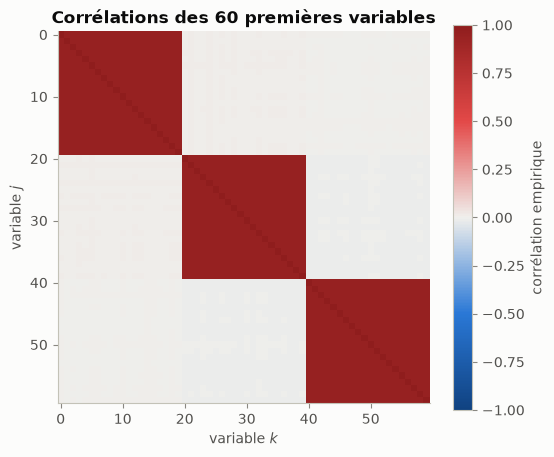

In [2]:
rng = np.random.RandomState(0)
X_big, y_big, beta, sigma = block_correlated_data(20000, rng=rng)
C = np.corrcoef(X_big[:, :60].T)
fig, ax = plt.subplots(figsize=(6, 5))
im = ax.imshow(C, cmap=DIV, vmin=-1, vmax=1)
fig.colorbar(im, ax=ax, label="corrélation empirique")
ax.set(title="Corrélations des 60 premières variables", xlabel="variable $k$",
       ylabel="variable $j$")
ax.grid(False)
plt.show()

In [3]:
same = np.kron(np.eye(3), np.ones((20, 20))).astype(bool) & ~np.eye(60, dtype=bool)
print("corrélation moyenne intra-bloc : %.3f" % C[same].mean())
print("corrélation moyenne inter-blocs : %.3f" % C[~np.kron(np.eye(3), np.ones((20, 20))).astype(bool)].mean())
print("un coefficient non nul par bloc :",
      np.all((beta.reshape(50, 20) != 0).sum(axis=1) == 1))
f_big = X_big @ beta
print("NSR empirique : %.3f (visé : 0,72)" % ((y_big - f_big).var() / f_big.var()))

corrélation moyenne intra-bloc : 0.950
corrélation moyenne inter-blocs : -0.001
un coefficient non nul par bloc : True
NSR empirique : 0.728 (visé : 0,72)
